In [1]:
# ===== STEP 4.1a: Install Unsloth =====
!pip install -q unsloth

In [2]:
# ===== STEP 4.1b: GPU check + load training data =====
import unsloth, torch, os, json
from google.colab import drive
from datasets import load_dataset

# GPU check
print("GPU available :", torch.cuda.is_available())
print("GPU name      :", torch.cuda.get_device_name(0))
print("Torch version :", torch.__version__)

# Drive + folders
drive.mount("/content/drive")
PROJECT  = "/content/drive/MyDrive/mistral-finetune"
DATA_DIR = f"{PROJECT}/data"
CKPT_DIR = f"{PROJECT}/checkpoints"     # training "save points"
os.makedirs(CKPT_DIR, exist_ok=True)

# Load the training manual + practice quiz (NOT the exam)
data = load_dataset("json", data_files={
    "train": f"{DATA_DIR}/train.jsonl",
    "val":   f"{DATA_DIR}/val.jsonl",
})
info = json.load(open(f"{DATA_DIR}/data_info.json"))
MAX_LEN = info["max_len_tokens"]

print("\n===== STEP 4.1 CHECK =====")
print("Train examples :", len(data["train"]))
print("Val examples   :", len(data["val"]))
print("MAX_LEN        :", MAX_LEN)
print("Columns        :", data["train"].column_names)
print("Checkpoints dir:", CKPT_DIR, "| exists:", os.path.exists(CKPT_DIR))
print("\nFirst training example:")
print(data["train"][0]["messages"])

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1126 03:33:27.962000 2730 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1126 03:33:28.005000 2730 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers does not load with torch 2.14.1+cu130, using PyTorch attention (UNSLOTH_ENABLE_LOGGING=1 for the fix).
🦥 Unsloth Zoo will now patch everything to make training faster!
GPU available : True
GPU name      : Tesla T4
Torch version : 2.14.1+cu130
Mounted at /content/drive


Generating train split: 0 examples [00:00, ? examples/s]

Generating val split: 0 examples [00:00, ? examples/s]


===== STEP 4.1 CHECK =====
Train examples : 4050
Val examples   : 216
MAX_LEN        : 1024
Columns        : ['messages', 'intent', 'category', 'n_tokens']
Checkpoints dir: /content/drive/MyDrive/mistral-finetune/checkpoints | exists: True

First training example:
[{'content': 'i dont know how to see ur money back policy', 'role': 'user'}, {'content': 'I\'ve understood, you need assistance in finding our money back policy. To help you with that, you can visit our website and navigate to the "Refund Policy" page. This page will provide you with all the information you need regarding our refund process, including the situations in which you can request a refund and the steps to follow.\n\nAdditionally, if you have any specific questions or concerns about our refund policy, feel free to let me know. I\'m here to provide you with any additional information or clarification you may need. Your satisfaction is our top priority.', 'role': 'assistant'}]


In [3]:
# ===== STEP 4.2: Load Mistral + attach LoRA adapter =====
from unsloth import FastLanguageModel

# 1) Load Mistral in 4-bit (same as Step 2.2)
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name="unsloth/mistral-7b-instruct-v0.3-bnb-4bit",
    max_seq_length=MAX_LEN,
    dtype=None,
    load_in_4bit=True,
)

# 2) Attach the empty "notebook of tips" (LoRA adapter)
model = FastLanguageModel.get_peft_model(
    model,
    r=16,                       # size of the notebook (how much it can learn)
    lora_alpha=16,              # how strongly the notebook's tips are applied
    lora_dropout=0,             # no random "forgetting" during training (Unsloth's recommended default)
    target_modules=[            # which parts of the brain get a notebook attached
        "q_proj", "k_proj", "v_proj", "o_proj",   # the "attention" parts (what to focus on)
        "gate_proj", "up_proj", "down_proj",      # the "thinking" parts (processing)
    ],
    bias="none",
    use_gradient_checkpointing="unsloth",   # memory saver: recompute instead of storing
    random_state=42,
)

# --- Checks ---
print("\n===== STEP 4.2 CHECK =====")
model.print_trainable_parameters()
used = torch.cuda.memory_allocated() / 1e9
free, total = torch.cuda.mem_get_info()
print(f"GPU memory used : {used:.1f} GB")
print(f"GPU memory free : {free/1e9:.1f} GB of {total/1e9:.1f} GB")

==((====))==  Unsloth 2026.11.12: Fast Mistral patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Unsloth 2026.11.12 patched 32 layers with 32 QKV layers, 32 O layers and 32 MLP layers.


Unsloth: compiling each transformer block as one region (MistralDecoderLayer).

===== STEP 4.2 CHECK =====
trainable params: 41,943,040 || all params: 7,289,966,592 || trainable%: 0.5754
GPU memory used : 4.3 GB
GPU memory free : 11.2 GB of 15.6 GB


In [4]:
# ===== STEP 4.3: Turn conversations into training text =====
BOS, EOS = tokenizer.bos_token, tokenizer.eos_token   # "<s>" and "</s>"

def to_text(batch):
    texts = []
    for msgs in batch["messages"]:
        t = tokenizer.apply_chat_template(msgs, tokenize=False)
        t = t.removeprefix(BOS)   # the training tool adds <s> itself, so avoid "<s><s>"
        texts.append(t)
    return {"text": texts}

train_ds = data["train"].map(to_text, batched=True, remove_columns=data["train"].column_names)
val_ds   = data["val"].map(to_text,   batched=True, remove_columns=data["val"].column_names)

# --- Checks ---
print("===== STEP 4.3 CHECK =====")
print("Train texts :", len(train_ds), "| Val texts:", len(val_ds))
print("Columns     :", train_ds.column_names)
print("All start with [INST]       :", all(t.startswith("[INST]") for t in train_ds["text"]))
print("All end with </s>           :", all(t.rstrip().endswith(EOS) for t in train_ds["text"]))
print("Any double <s>              :", any(t.startswith(BOS) for t in train_ds["text"]))
print("All contain [/INST] exactly once:", all(t.count("[/INST]") == 1 for t in train_ds["text"]))

print("\n----- Example training text -----")
print(train_ds[0]["text"])

Map:   0%|          | 0/4050 [00:00<?, ? examples/s]

Map:   0%|          | 0/216 [00:00<?, ? examples/s]

===== STEP 4.3 CHECK =====
Train texts : 4050 | Val texts: 216
Columns     : ['text']
All start with [INST]       : True
All end with </s>           : True
Any double <s>              : False
All contain [/INST] exactly once: True

----- Example training text -----
[INST] i dont know how to see ur money back policy[/INST] I've understood, you need assistance in finding our money back policy. To help you with that, you can visit our website and navigate to the "Refund Policy" page. This page will provide you with all the information you need regarding our refund process, including the situations in which you can request a refund and the steps to follow.

Additionally, if you have any specific questions or concerns about our refund policy, feel free to let me know. I'm here to provide you with any additional information or clarification you may need. Your satisfaction is our top priority.</s>


In [5]:
# ===== STEP 4.4: Training settings + trainer + learn only from answers =====
import math
from trl import SFTTrainer, SFTConfig
from unsloth import is_bf16_supported
from unsloth.chat_templates import train_on_responses_only

BATCH, GRAD_ACC = 2, 4           # 2 examples at a time x 4 = learns from 8 examples per step
EFFECTIVE_BATCH = BATCH * GRAD_ACC
TOTAL_STEPS = math.ceil(len(train_ds) / EFFECTIVE_BATCH)

args = SFTConfig(
    output_dir=CKPT_DIR,              # save points go to Drive
    dataset_text_field="text",
    packing=False,
    # --- how it learns ---
    per_device_train_batch_size=BATCH,
    gradient_accumulation_steps=GRAD_ACC,
    num_train_epochs=1,               # read the whole manual once
    learning_rate=2e-4,               # how big each learning "step" is
    lr_scheduler_type="linear",       # start at full speed, slow down gradually
    warmup_steps=10,                  # gentle start for the first 10 steps
    weight_decay=0.01,
    optim="adamw_8bit",               # memory-saving optimiser
    fp16=not is_bf16_supported(),     # T4 uses float16
    bf16=is_bf16_supported(),
    # --- progress reports & quiz ---
    logging_steps=10,                 # print progress every 10 steps
    eval_strategy="steps",
    eval_steps=100,                   # take the practice quiz every 100 steps
    per_device_eval_batch_size=4,
    # --- save points ---
    save_strategy="steps",
    save_steps=50,                    # save progress every 50 steps
    save_total_limit=3,               # keep only the 3 most recent saves (saves Drive space)
    # --- other ---
    seed=42,
    report_to="none",
)

trainer = SFTTrainer(
    model=model,
    processing_class=tokenizer,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    args=args,
)

# Learn ONLY from the agent's answers (hide the customer's part from scoring)
trainer = train_on_responses_only(
    trainer,
    instruction_part="[INST]",
    response_part="[/INST]",
)

# --- Checks ---
row    = trainer.train_dataset[0]
ids    = row["input_ids"]
labels = row["labels"]
learned = [t for t in labels if t != -100]          # -100 = hidden from scoring

print("===== STEP 4.4 CHECK =====")
print("Effective batch size :", EFFECTIVE_BATCH)
print("Total training steps :", TOTAL_STEPS)
print("Starts with ONE <s>  :", ids[0] == tokenizer.bos_token_id and ids[1] != tokenizer.bos_token_id)
print(f"Tokens hidden (question part): {len(ids) - len(learned)} of {len(ids)}")
print("\n----- FULL text the model READS -----")
print(tokenizer.decode(ids))
print("\n----- ONLY the part it is GRADED on -----")
print(tokenizer.decode(learned))

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/4050 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/216 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Map:   0%|          | 0/4050 [00:00<?, ? examples/s]

Map:   0%|          | 0/216 [00:00<?, ? examples/s]

===== STEP 4.4 CHECK =====
Effective batch size : 8
Total training steps : 507
Starts with ONE <s>  : True
Tokens hidden (question part): 13 of 133

----- FULL text the model READS -----
<s>[INST] i dont know how to see ur money back policy[/INST] I've understood, you need assistance in finding our money back policy. To help you with that, you can visit our website and navigate to the "Refund Policy" page. This page will provide you with all the information you need regarding our refund process, including the situations in which you can request a refund and the steps to follow.

Additionally, if you have any specific questions or concerns about our refund policy, feel free to let me know. I'm here to provide you with any additional information or clarification you may need. Your satisfaction is our top priority.</s>

----- ONLY the part it is GRADED on -----
I've understood, you need assistance in finding our money back policy. To help you with that, you can visit our website and navig

In [6]:
# ===== STEP 4.5: TRAIN =====
import glob, time

# Resume from the latest save point if one exists (after a disconnect)
ckpts  = sorted(glob.glob(f"{CKPT_DIR}/checkpoint-*"), key=lambda p: int(p.split("-")[-1]))
resume = ckpts[-1] if ckpts else None
print("Resuming from:", resume if resume else "nothing (fresh start)")

torch.cuda.reset_peak_memory_stats()
start = time.time()

stats = trainer.train(resume_from_checkpoint=resume)

minutes = (time.time() - start) / 60
peak    = torch.cuda.max_memory_allocated() / 1e9
print(f"\n✅ TRAINING FINISHED in {minutes:.1f} minutes | peak GPU memory: {peak:.1f} GB")

Resuming from: nothing (fresh start)


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 4,050 | Num Epochs = 1 | Total steps = 507
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 41,943,040 of 7,289,966,592 (0.58% trained)


Unsloth: packed / padding-free rows run each transformer block uncompiled; only unpacked batches use the compiled blocks.
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,Validation Loss
100,0.705077,0.687743
200,0.604485,0.631961
300,0.628288,0.613157
400,0.525174,0.586060
500,0.545589,0.569831
507,0.545589,0.569670


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/mistral-finetune/checkpoints/checkpoint-50/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/drive/MyDrive/mistral-finetune/checkpoints/checkpoint-50.


Filter:   0%|          | 0/216 [00:00<?, ? examples/s]

Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/mistral-finetune/checkpoints/checkpoint-100/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/drive/MyDrive/mistral-finetune/checkpoints/checkpoint-100.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/mistral-finetune/checkpoints/checkpoint-150/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/drive/MyDrive/mistral-finetune/checkpoints/checkpoint-150.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/mistral-finetune/checkpoints/checkpoint-200/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/drive/MyDrive/mistral-finetune/checkpoints/checkpoint-200.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/mistral-finetune/checkpoints/checkpoint-250/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.mo


✅ TRAINING FINISHED in 41.5 minutes | peak GPU memory: 14.2 GB


In [7]:
# ===== STEP 4.6: Save the trained adapter + try it =====
ADAPTER_DIR = f"{PROJECT}/adapter_final"

# 1) Save the notebook of tips (LoRA adapter) + tokenizer to Drive
model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)

print("===== STEP 4.6 CHECK =====")
for f in sorted(os.listdir(ADAPTER_DIR)):
    print(f"  {f:<35} {os.path.getsize(f'{ADAPTER_DIR}/{f}')/1e6:8.1f} MB")

# 2) Try the same question as Step 2.3
FastLanguageModel.for_inference(model)
question = "I want to cancel my order, how do I do it?"
text   = tokenizer.apply_chat_template([{"role": "user", "content": question}],
                                       tokenize=False, add_generation_prompt=True)
inputs = tokenizer(text, return_tensors="pt", add_special_tokens=False).to("cuda")
out    = model.generate(**inputs, max_new_tokens=400, do_sample=False,
                        pad_token_id=tokenizer.eos_token_id)
new    = out[0][inputs["input_ids"].shape[1]:]
answer = tokenizer.decode(new, skip_special_tokens=True).strip()

print("\nCUSTOMER:", question)
print("\nTRAINED MISTRAL:\n", answer)
print("\nAnswer length (words):", len(answer.split()), "| stopped on its own:", len(new) < 400)

Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/mistral-finetune/adapter_final/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/drive/MyDrive/mistral-finetune/adapter_final.


===== STEP 4.6 CHECK =====
  README.md                                0.0 MB
  adapter_config.json                      0.0 MB
  adapter_model.safetensors              167.8 MB
  chat_template.jinja                      0.0 MB
  tokenizer.json                           3.7 MB
  tokenizer.model                          0.6 MB
  tokenizer_config.json                    0.1 MB


Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



CUSTOMER: I want to cancel my order, how do I do it?

TRAINED MISTRAL:
 I've understood, you're looking to cancel your order. We're here to assist you with that. To cancel your order, please follow these steps:

1. Sign in to your account: Access our platform by logging into your {{Online Company Portal Info}}.
2. Locate your order: Once logged in, navigate to the '{{Online Order Interaction}}' or '{{Online Order Interaction}}' section.
3. Find the specific order: Look for the order associated with the purchase you want to cancel.
4. Initiate the cancellation: Click on the order to access the details. You should see an option labeled '{{Online Order Interaction}}' or similar.
5. Confirm the cancellation: Follow the prompts to confirm the cancellation of your order.

If you encounter any difficulties or have further questions, our dedicated support team is available to assist you. You can reach us during {{Customer Support Hours}} at {{Customer Support Phone Number}} or through the Liv

In [8]:
# ===== STEP 5.1: Trained model takes the exam (version C) =====
import json, time, os, torch
from tqdm.auto import tqdm
from datasets import load_dataset

RES_DIR = f"{PROJECT}/results"
test_ds = load_dataset("json", data_files=f"{DATA_DIR}/test.jsonl", split="train")
print("Exam questions:", len(test_ds))

FastLanguageModel.for_inference(model)
tokenizer.padding_side = "left"
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def build_prompt(question, system_prompt=None):
    msgs = [{"role": "user", "content": question}]
    if system_prompt:
        msgs = [{"role": "system", "content": system_prompt}] + msgs
    return tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

def run_exam(out_name, system_prompt=None, batch_size=8, max_new_tokens=400):
    """Same exam method as Step 3.2: batched, saved after every batch, resumable."""
    out_path = f"{RES_DIR}/{out_name}.jsonl"
    done = set()
    if os.path.exists(out_path):
        with open(out_path) as f:
            done = {json.loads(line)["id"] for line in f}
    todo = [i for i in range(len(test_ds)) if i not in done]
    print(f"{out_name}: {len(done)} already done, {len(todo)} to go")

    start = time.time()
    for b in tqdm(range(0, len(todo), batch_size), desc=out_name):
        ids  = todo[b:b + batch_size]
        rows = [test_ds[i] for i in ids]
        qs   = [r["messages"][0]["content"] for r in rows]
        inputs = tokenizer([build_prompt(q, system_prompt) for q in qs],
                           return_tensors="pt", padding=True,
                           add_special_tokens=False).to("cuda")
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=max_new_tokens,
                                 do_sample=False, pad_token_id=tokenizer.pad_token_id)
        new_tokens = out[:, inputs["input_ids"].shape[1]:]
        with open(out_path, "a") as f:
            for i, r, q, toks in zip(ids, rows, qs, new_tokens):
                f.write(json.dumps({
                    "id": i, "intent": r["intent"], "category": r["category"],
                    "question": q, "reference": r["messages"][1]["content"],
                    "answer": tokenizer.decode(toks, skip_special_tokens=True).strip(),
                    "n_tokens": int((toks != tokenizer.pad_token_id).sum()),
                }) + "\n")
    print(f"Finished in {(time.time() - start) / 60:.1f} minutes -> {out_path}")

# --- Run version C: trained model, no instruction ---
run_exam("finetuned_C", system_prompt=None)

Generating train split: 0 examples [00:00, ? examples/s]

Exam questions: 200
finetuned_C: 0 already done, 200 to go


finetuned_C:   0%|          | 0/25 [00:00<?, ?it/s]

Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Finished in 10.9 minutes -> /content/drive/MyDrive/mistral-finetune/results/finetuned_C.jsonl


In [9]:
# ===== STEP 5.2: Scoreboard A vs B vs C =====
import os, pandas as pd
from google.colab import drive
drive.mount("/content/drive")

RES_DIR = "/content/drive/MyDrive/mistral-finetune/results"
load = lambda name: pd.read_json(f"{RES_DIR}/{name}.jsonl", lines=True).sort_values("id").reset_index(drop=True)
A, B, C = load("baseline_A_plain"), load("baseline_B_system"), load("finetuned_C")
ideal = A.assign(answer=A["reference"])
print("Answers loaded -> A:", len(A), "| B:", len(B), "| C:", len(C))

AI_TALK = r"as an ai|i'm an ai|i am an ai|language model|don't have access|do not have access|i cannot access"
# Real-looking emails / web addresses / phone numbers (not {{placeholders}})
INVENTED = r"[\w.\-]+@[\w\-]+\.\w+|www\.\w+|https?://|\b\d{3}[\s\-.]\d{3}[\s\-.]\d{4}\b|1-800"

def signals(df, name):
    ans = df["answer"].str.lower()
    return {
        "version": name,
        "uses {{placeholders}} %": round(df["answer"].str.contains(r"\{\{").mean() * 100, 1),
        "says 'as an AI'/'no access' %": round(ans.str.contains(AI_TALK).mean() * 100, 1),
        "invents contact details %": round(ans.str.contains(INVENTED).mean() * 100, 1),
        "letter sign-off '[Your Name]' %": round(ans.str.contains(r"\[your name\]").mean() * 100, 1),
        "avg words": int(df["answer"].str.split().str.len().mean()),
    }

board = pd.DataFrame([
    signals(A, "A plain (before)"),
    signals(B, "B + instruction (before)"),
    signals(C, "C TRAINED (after)"),
    signals(ideal, "IDEAL (target)"),
])
print("\n===== SCOREBOARD: BEFORE vs AFTER =====")
print(board.to_string(index=False))
board.to_csv(f"{RES_DIR}/final_scoreboard.csv", index=False)
print("\nSaved -> final_scoreboard.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Answers loaded -> A: 200 | B: 200 | C: 200

===== SCOREBOARD: BEFORE vs AFTER =====
                 version  uses {{placeholders}} %  says 'as an AI'/'no access' %  invents contact details %  letter sign-off '[Your Name]' %  avg words
        A plain (before)                     11.0                            3.0                        3.0                              4.5        186
B + instruction (before)                     19.0                            0.0                       10.0                             70.5        200
       C TRAINED (after)                     48.5                            0.0                        0.0                              0.0        100
          IDEAL (target)                     52.0                            0.5                        0.5                              0.0        103

Saved -> final_scoreboard.

In [10]:
# ===== STEP 6.1: Upload the adapter to Hugging Face =====
from google.colab import userdata
HF_TOKEN     = userdata.get("HF_TOKEN")
REPO_ADAPTER = "pramod586/mistral-7b-customer-support-lora"

model.push_to_hub(REPO_ADAPTER, token=HF_TOKEN, private=False)
tokenizer.push_to_hub(REPO_ADAPTER, token=HF_TOKEN)
print("✅ Uploaded -> https://huggingface.co/" + REPO_ADAPTER)

README.md:   0%|          | 0.00/586 [00:00<?, ?B/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...adapter_model.safetensors:   0%|          |  556kB /  168MB            

Validating                    :           |   0%            

Saved model to https://huggingface.co/pramod586/mistral-7b-customer-support-lora


... (2 outputs left out)

New Data Upload               : |          |  0.00B /  0.00B            

  ...p25b0pxry/tokenizer.model: 100%|##########|  587kB /  587kB            

Validating                    :           |   0%            

✅ Uploaded -> https://huggingface.co/pramod586/mistral-7b-customer-support-lora


In [11]:
# ===== STEP 7.1: Merge + convert to GGUF (Q4_K_M) + upload =====
import glob, os, time
from huggingface_hub import HfApi
from google.colab import userdata

HF_TOKEN  = userdata.get("HF_TOKEN")
REPO_GGUF = "pramod586/mistral-7b-customer-support-GGUF"
GGUF_DIR  = "/content/gguf_out"     # Colab's local disk (fast); NOT Drive
start = time.time()

# 1) Merge adapter into Mistral + convert to GGUF + compress to Q4_K_M
model.save_pretrained_gguf(GGUF_DIR, tokenizer, quantization_method="q4_k_m")

# 2) Find the Q4_K_M file (Unsloth may name the folder/file slightly differently)
files = glob.glob(f"{GGUF_DIR}*/**/*.gguf", recursive=True) + glob.glob(f"{GGUF_DIR}*/*.gguf")
files = sorted(set(files))
print("\nGGUF files created:")
for f in files:
    print(f"  {f}  ({os.path.getsize(f)/1e9:.2f} GB)")
q4 = [f for f in files if "q4_k_m" in f.lower()][0]

# 3) Upload ONLY the Q4_K_M file to Hugging Face
api = HfApi(token=HF_TOKEN)
api.create_repo(REPO_GGUF, exist_ok=True, private=False)
api.upload_file(
    path_or_fileobj=q4,
    path_in_repo="mistral-7b-customer-support-Q4_K_M.gguf",
    repo_id=REPO_GGUF,
)
print(f"\n✅ Done in {(time.time()-start)/60:.1f} min -> https://huggingface.co/{REPO_GGUF}")

Unsloth: ##### The current model auto adds a BOS token.
Unsloth: ##### Your chat template has a BOS token. We shall remove it temporarily.


Unsloth: Merging model weights to 16-bit format...


config.json:   0%|          | 0.00/724 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Unsloth: Restored added_tokens_decoder metadata in /content/gguf_out/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/gguf_out.


Found HuggingFace hub cache directory: /root/.cache/huggingface/hub


... (17 outputs left out)

New Data Upload               : |          |  0.00B /  0.00B            

  ...instruct-v0.3.Q4_K_M.gguf:   0%|          | 1.70MB / 4.37GB            

Validating                    :           |   0%            


✅ Done in 40.2 min -> https://huggingface.co/pramod586/mistral-7b-customer-support-GGUF


In [12]:
# ===== STEP 5.3: Similarity grade =====
!pip install -q rouge_score sentence-transformers
from rouge_score import rouge_scorer
from sentence_transformers import SentenceTransformer, util

# 1) ROUGE-L: shared wording with the ideal answer
scorer = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)
def rougeL(df):
    return pd.Series([scorer.score(ref, ans)["rougeL"].fmeasure
                      for ref, ans in zip(df["reference"], df["answer"])])

# 2) Meaning similarity: a small AI model compares the meaning of two texts
embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
ref_emb  = embedder.encode(A["reference"].tolist(), convert_to_tensor=True, batch_size=32)
def meaning(df):
    ans_emb = embedder.encode(df["answer"].tolist(), convert_to_tensor=True, batch_size=32)
    return pd.Series(util.cos_sim(ans_emb, ref_emb).diagonal().cpu().numpy())

scores = {}
for name, df in [("A plain (before)", A), ("B + instruction (before)", B), ("C TRAINED (after)", C)]:
    scores[name] = {"rougeL": rougeL(df), "meaning": meaning(df)}

sim = pd.DataFrame([{
    "version": name,
    "ROUGE-L (wording, 0-1)":   round(s["rougeL"].mean(), 3),
    "Meaning similarity (0-1)": round(s["meaning"].mean(), 3),
} for name, s in scores.items()])

c_beats_b = (scores["C TRAINED (after)"]["meaning"] > scores["B + instruction (before)"]["meaning"]).mean() * 100
c_beats_a = (scores["C TRAINED (after)"]["meaning"] > scores["A plain (before)"]["meaning"]).mean() * 100

print("===== STEP 5.3: SIMILARITY TO IDEAL ANSWERS (higher = better) =====")
print(sim.to_string(index=False))
print(f"\nC is closer in meaning than A on {c_beats_a:.0f}% of the 200 questions")
print(f"C is closer in meaning than B on {c_beats_b:.0f}% of the 200 questions")
sim.to_csv(f"{RES_DIR}/final_similarity.csv", index=False)
print("\nSaved -> final_similarity.csv")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

===== STEP 5.3: SIMILARITY TO IDEAL ANSWERS (higher = better) =====
                 version  ROUGE-L (wording, 0-1)  Meaning similarity (0-1)
        A plain (before)                   0.186                     0.674
B + instruction (before)                   0.222                     0.703
       C TRAINED (after)                   0.454                     0.875

C is closer in meaning than A on 97% of the 200 questions
C is closer in meaning than B on 96% of the 200 questions

Saved -> final_similarity.csv


In [13]:
# ===== STEP 5.4: Side-by-side examples (same 5 questions as Step 3.4) =====
picks = A.drop_duplicates("intent").sample(5, random_state=7).index   # same picks as Step 3.4

md = ["# Before vs After - sample answers\n"]
for i in picks:
    md.append(
        f"\n## {A.loc[i,'intent']}\n"
        f"**CUSTOMER:** {A.loc[i,'question']}\n\n"
        f"**A - plain Mistral (before):**\n{A.loc[i,'answer']}\n\n"
        f"**B - Mistral + instruction (before):**\n{B.loc[i,'answer']}\n\n"
        f"**C - TRAINED Mistral (after):**\n{C.loc[i,'answer']}\n\n"
        f"**IDEAL (Bitext reference):**\n{A.loc[i,'reference']}\n"
    )
with open(f"{RES_DIR}/final_samples.md", "w") as f:
    f.write("\n".join(md))

# Print a short version on screen
for i in picks:
    print(f"\n==================== {A.loc[i,'intent']} ====================")
    print("CUSTOMER :", A.loc[i, "question"])
    print("\nB (before):", B.loc[i, "answer"][:300], "...")
    print("\nC (after) :", C.loc[i, "answer"][:300], "...")
    print("\nIDEAL    :", A.loc[i, "reference"][:300], "...")

print("\nSaved:", sorted(os.listdir(RES_DIR)))


==================== get_invoice ====================
CUSTOMER : get invoice #00108

B (before): Dear Customer,

Thank you for reaching out to us. I'm more than happy to help you with your inquiry regarding Invoice #00108.

To provide you with the necessary details, I've checked our records and found the following information:

Invoice #00108:
- Date: [Invoice Date]
- Total Amount: $[Total Amou ...

C (after) : I'm on it! I completely understand your need to access the invoice with the number #{{Invoice Number}}. Let me assist you with that. Could you please provide me with some additional information such as the date range or any specific details related to the invoice? This will help me locate the invoic ...

IDEAL    : I've deduced from your message that you need assistance with getting your invoice with the number #{{Invoice Number}}. Give me a moment to retrieve that for you. While I'm doing that, is there anything else I can help you with? ...

==================== track_order =

Mounted at /content/drive
Drive connected : True
Results folder  : True
Checkpoints     : ['README.md', 'checkpoint-450', 'checkpoint-500', 'checkpoint-507']


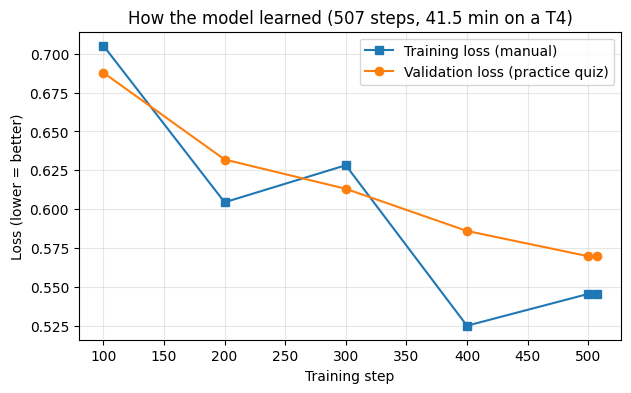

===== FIX CHECK =====
 step     loss  eval_loss
  100 0.705077   0.687743
  200 0.604485   0.631961
  300 0.628288   0.613157
  400 0.525174   0.586060
  500 0.545589   0.569831
  507 0.545589   0.569670

Saved: ['training_log.csv', 'training_loss.png']


In [4]:
# ===== FIX: Rebuild training log + chart from the printed training table =====

# ===== Connect Google Drive =====
from google.colab import drive
import os
drive.mount("/content/drive")

RES_DIR = "/content/drive/MyDrive/mistral-finetune/results"
print("Drive connected :", os.path.exists("/content/drive/MyDrive"))
print("Results folder  :", os.path.exists(RES_DIR))
print("Checkpoints     :", sorted(os.listdir("/content/drive/MyDrive/mistral-finetune/checkpoints")))

import os
import pandas as pd
import matplotlib.pyplot as plt

RES_DIR = "/content/drive/MyDrive/mistral-finetune/results"

# Numbers copied from the Step 4.5 output table
rows = [
    (100, 0.705077, 0.687743),
    (200, 0.604485, 0.631961),
    (300, 0.628288, 0.613157),
    (400, 0.525174, 0.586060),
    (500, 0.545589, 0.569831),
    (507, 0.545589, 0.569670),
]
hist = pd.DataFrame(rows, columns=["step", "loss", "eval_loss"])
hist.to_csv(f"{RES_DIR}/training_log.csv", index=False)

plt.figure(figsize=(7, 4))
plt.plot(hist["step"], hist["loss"], "s-", label="Training loss (manual)")
plt.plot(hist["step"], hist["eval_loss"], "o-", label="Validation loss (practice quiz)")
plt.xlabel("Training step"); plt.ylabel("Loss (lower = better)")
plt.title("How the model learned (507 steps, 41.5 min on a T4)")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig(f"{RES_DIR}/training_loss.png", dpi=120, bbox_inches="tight")
plt.show()

print("===== FIX CHECK =====")
print(hist.to_string(index=False))
print("\nSaved:", [f for f in sorted(os.listdir(RES_DIR)) if f.startswith("training")])

In [5]:
# ===== STEP 6.2: Model card for the adapter (fixed) =====
import pandas as pd
from huggingface_hub import HfApi
from google.colab import userdata

api = HfApi(token=userdata.get("HF_TOKEN"))
REPO_ADAPTER = "pramod586/mistral-7b-customer-support-lora"
REPO_GGUF    = "pramod586/mistral-7b-customer-support-GGUF"
FENCE = "`" * 3   # triple backtick, generated so the chat doesn't break the block

# Read our real results from Drive
board = pd.read_csv(f"{RES_DIR}/final_scoreboard.csv")
sim   = pd.read_csv(f"{RES_DIR}/final_similarity.csv")
log   = pd.read_csv(f"{RES_DIR}/training_log.csv")
tr, ev = log.dropna(subset=["loss"]), log.dropna(subset=["eval_loss"])

def md_table(df):
    cols  = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in df.values]
    return "\n".join(lines)

usage_code = "\n".join([
    FENCE + "python",
    "from unsloth import FastLanguageModel",
    "",
    "model, tokenizer = FastLanguageModel.from_pretrained(",
    f'    "{REPO_ADAPTER}", max_seq_length=1024, load_in_4bit=True)',
    "FastLanguageModel.for_inference(model)",
    "",
    'messages = [{"role": "user", "content": "I want to cancel my order, how do I do it?"}]',
    "text   = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)",
    'inputs = tokenizer(text, return_tensors="pt", add_special_tokens=False).to("cuda")',
    "out    = model.generate(**inputs, max_new_tokens=400, do_sample=False)",
    'print(tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True))',
    FENCE,
])